In [1]:
import numpy as np
import pandas as pd
import matplotlib . pyplot as plt
from sklearn . datasets import fetch_california_housing
# Load the dataset
housing = fetch_california_housing ()
df = pd . DataFrame ( housing . data , columns = housing . feature_names )
df ['MedHouseVal'] = housing . target # target in $100 ,000 s
print ( f'Dataset shape : {df. shape }')
print ( f'\ nFeature names :\n{ housing . feature_names }')
print ( f'\ nFirst 5 rows :')
print ( df.head() )
print ( f'\nBasic statistics :')
print ( df.describe().round(3) )

<>:10: SyntaxWarning: invalid escape sequence '\ '
<>:11: SyntaxWarning: invalid escape sequence '\ '
<>:10: SyntaxWarning: invalid escape sequence '\ '
<>:11: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_209/374952372.py:10: SyntaxWarning: invalid escape sequence '\ '
  print ( f'\ nFeature names :\n{ housing . feature_names }')
/tmp/ipykernel_209/374952372.py:11: SyntaxWarning: invalid escape sequence '\ '
  print ( f'\ nFirst 5 rows :')


Dataset shape : (20640, 9)
\ nFeature names :
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
\ nFirst 5 rows :
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Basic statistics :
          MedInc   HouseAge   AveRooms  AveBedrms  Population   AveOccup  \
count  20640.000  20640.000  20640.000  20640.000   20640.000  20640.000   
mean       3.871     28.639      5.429  

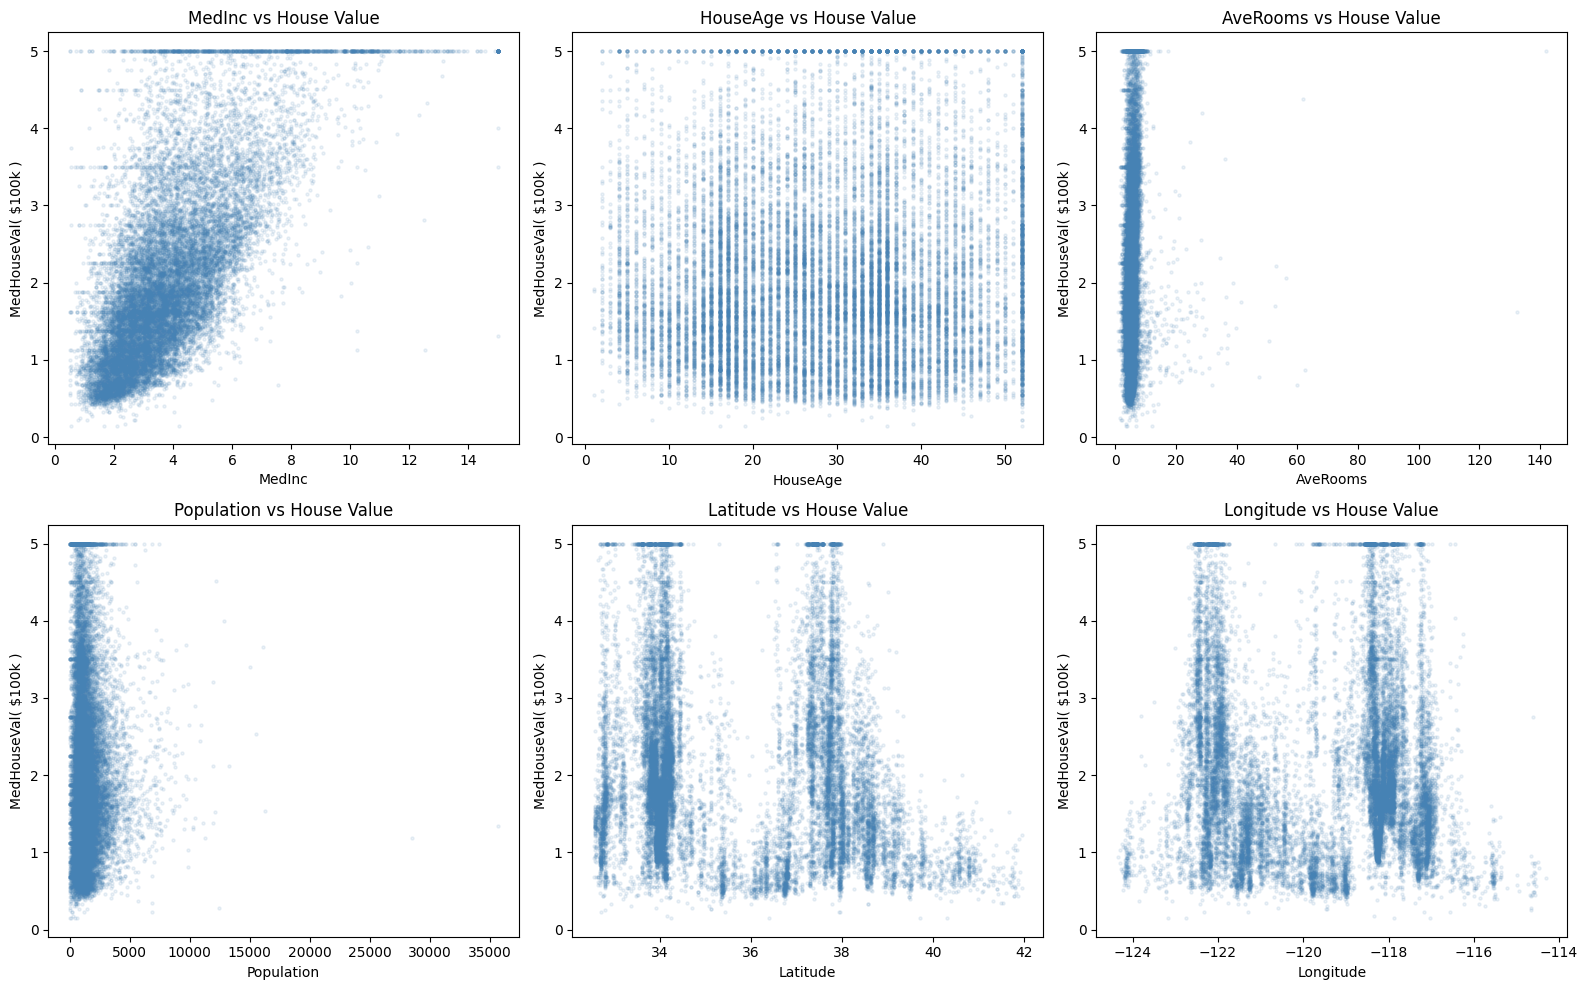

In [4]:
fig,axes = plt.subplots (2 , 3 , figsize =(16 , 10) )
features_to_plot = ['MedInc', 'HouseAge', 'AveRooms',
'Population', 'Latitude', 'Longitude']
for ax,feat in zip(axes.flatten() , features_to_plot):
  ax.scatter(df[feat] , df['MedHouseVal'] ,
             alpha =0.1 , s =5 , color ='steelblue')
  ax.set_xlabel(feat)
  ax.set_ylabel('MedHouseVal( $100k )')
  ax.set_title( f'{ feat } vs House Value')

plt.tight_layout()
plt.show()

In [5]:
df.corr()['MedHouseVal'].sort_values()

,MedHouseVal
Latitude,-0.144160
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737
HouseAge,0.105623
AveRooms,0.151948
MedInc,0.688075
MedHouseVal,1.000000


(array([   9.,   14.,   61.,  255.,  538.,  676.,  546.,  803.,  881.,
         706.,  812.,  715.,  836.,  815.,  921.,  960.,  786.,  817.,
         703.,  505.,  620.,  661.,  578.,  508.,  432.,  439.,  463.,
         331.,  320.,  216.,  224.,  232.,  245.,  252.,  286.,  193.,
         160.,  149.,  117.,  133.,  104.,   99.,   80.,   90.,  106.,
          66.,   49.,   51.,   47., 1030.]),
 array([0.14999  , 0.2469904, 0.3439908, 0.4409912, 0.5379916, 0.634992 ,
        0.7319924, 0.8289928, 0.9259932, 1.0229936, 1.119994 , 1.2169944,
        1.3139948, 1.4109952, 1.5079956, 1.604996 , 1.7019964, 1.7989968,
        1.8959972, 1.9929976, 2.089998 , 2.1869984, 2.2839988, 2.3809992,
        2.4779996, 2.575    , 2.6720004, 2.7690008, 2.8660012, 2.9630016,
        3.060002 , 3.1570024, 3.2540028, 3.3510032, 3.4480036, 3.545004 ,
        3.6420044, 3.7390048, 3.8360052, 3.9330056, 4.030006 , 4.1270064,
        4.2240068, 4.3210072, 4.4180076, 4.515008 , 4.6120084, 4.7090088,
        

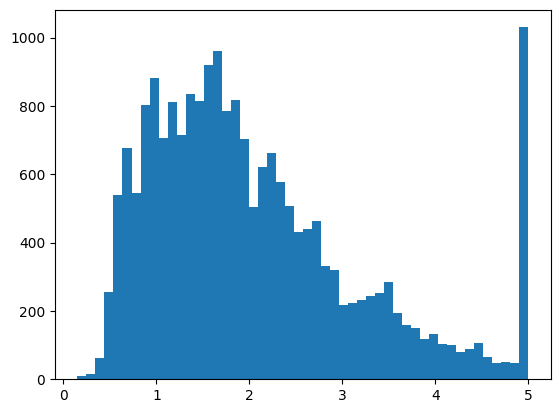

In [6]:
plt.hist(df['MedHouseVal'], bins=50)

In [7]:
df.shape

(20640, 9)

## Task1

1. Which feature has the strongest correlation with the target?
**MedHouseVal**

2. Is MedHouseVal normally distributed? Is there a cap at 5.0?
 **The distribution is not perfectly normal. It is right-skewed, meaning most values are lower and fewer are very high, there is a clear cap at 5.0, which means the dataset limits house prices at $500,000.**

3. How many samples are in the dataset? Is it enough? **The dataset contains 20,640 samples, This is enough.**

In [8]:
from sklearn.model_selection import train_test_split
X_simple = df[['MedInc']].values
y = df['MedHouseVal'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


Slope (w1):       0.4193
Intercept (w0):   0.4446

Equation: y = 0.4193 * MedInc + (0.4446)


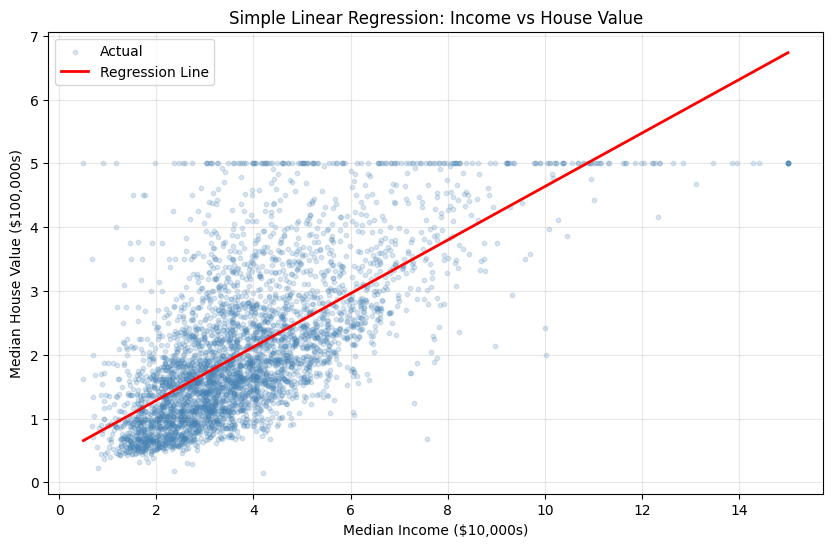

In [9]:
from sklearn.linear_model import LinearRegression

# Train
model_simple = LinearRegression()
model_simple.fit(X_train, y_train)

# Print the learned parameters
print(f'Slope (w1):       {model_simple.coef_[0]:.4f}')
print(f'Intercept (w0):   {model_simple.intercept_:.4f}')
print(f'\nEquation: y = {model_simple.coef_[0]:.4f} * MedInc '
      f'+ ({model_simple.intercept_:.4f})')

# Visualize: scatter + regression line
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, alpha=0.2, s=10,
            color='steelblue', label='Actual')

# Draw the regression line
x_line = np.linspace(X_test.min(), X_test.max(), 100)
y_line = model_simple.predict(x_line.reshape(-1, 1))
plt.plot(x_line, y_line, color='red', linewidth=2,
         label='Regression Line')

plt.xlabel('Median Income ($10,000s)')
plt.ylabel('Median House Value ($100,000s)')
plt.title('Simple Linear Regression: Income vs House Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
prediction = model_simple.predict([[5.0]])
print(prediction)

[2.54128976]


In [17]:
from sklearn.metrics import mean_squared_error, r2_score

# Use HouseAge as the feature
X_simple = df[['HouseAge']].values
y = df['MedHouseVal'].values

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Train model
model_age = LinearRegression()
model_age.fit(X_train, y_train)

# Predictions
y_pred_age = model_age.predict(X_test)

# Evaluate
rmse_age = np.sqrt(mean_squared_error(y_test, y_pred_age))
r2_age = r2_score(y_test, y_pred_age)

print("HouseAge Model RMSE:", rmse_age)
print("HouseAge Model R2:", r2_age)

HouseAge Model RMSE: 1.1375243850177597
HouseAge Model R2: 0.012551235533311389


##Task2

1. **Equation:** **y** **=** **0.4193** * **MedInc** **+** **(0.4446)**
2. **2.54128976**
3. **Performance:(Median Income) is a much stronger predictor of house, because HouseAge has a weaker relationship with house prices, while median income is a stronger predictor of house value. **

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Predictions
y_pred_simple = model_simple.predict(X_test)

# Calculate metrics
mse = mean_squared_error(y_test, y_pred_simple)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_simple)
r2 = r2_score(y_test, y_pred_simple)

print('=== Simple Linear Regression (MedInc only) ===')
print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f} (error in $100,000s)')
print(f'MAE: {mae:.4f} (error in $100,000s)')
print(f'R^2: {r2:.4f} ({r2*100:.1f}% variance explained)')

=== Simple Linear Regression (MedInc only) ===
MSE: 136.7304
RMSE: 11.6932 (error in $100,000s)
MAE: 10.4743 (error in $100,000s)
R^2: -103.3418 (-10334.2% variance explained)


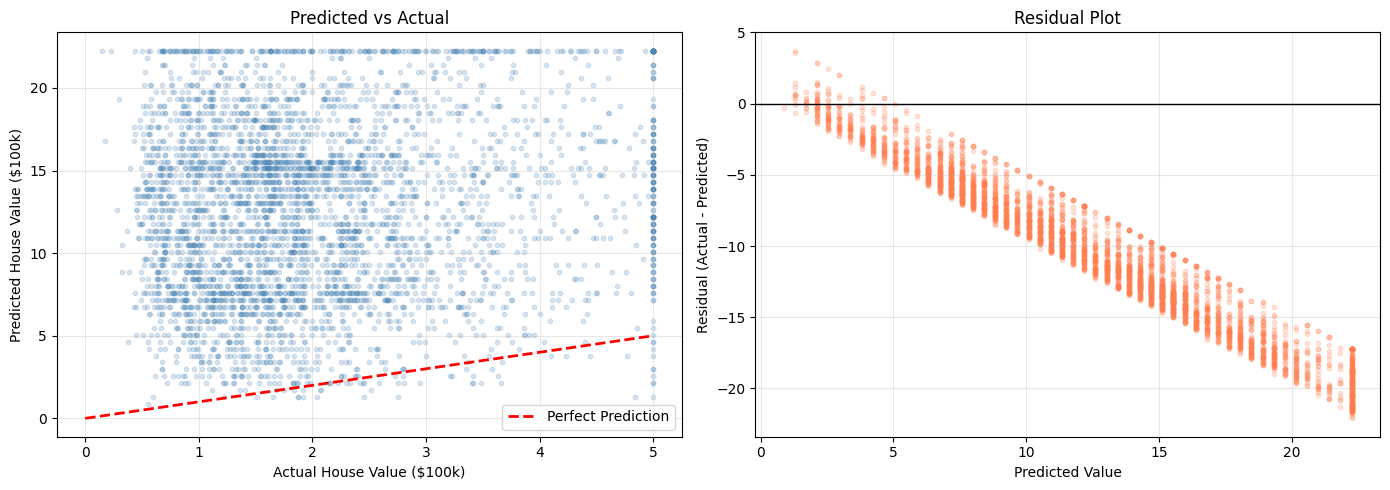

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Predicted vs Actual
axes[0].scatter(y_test, y_pred_simple, alpha=0.2, s=10, color='steelblue')
axes[0].plot([0, 5], [0, 5], 'r--', linewidth=2, label='Perfect Prediction')

axes[0].set_xlabel('Actual House Value ($100k)')
axes[0].set_ylabel('Predicted House Value ($100k)')
axes[0].set_title('Predicted vs Actual')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Residuals (errors)
residuals = y_test - y_pred_simple
axes[1].scatter(y_pred_simple, residuals, alpha=0.2, s=10, color='coral')
axes[1].axhline(y=0, color='black', linewidth=1)

axes[1].set_xlabel('Predicted Value')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Plot')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##Task3

1. 0.74×100,000=74,000
2. the model struggles more at high house values, the model can't predict high prices.
3. The R² value shows that a single feature is not enough to predict house prices well

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use all features
X_all = df.drop(columns=['MedHouseVal']).values
y = df['MedHouseVal'].values

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

# Build pipeline with scaling (good practice!)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression())
])

pipe_lr.fit(X_train, y_train)
y_pred_multi = pipe_lr.predict(X_test)

# Evaluate
r2_multi = r2_score(y_test, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))

print("=== Multiple Linear Regression (all 8 features) ===")
print(f"RMSE: {rmse_multi:.4f}")
print(f"R^2: {r2_multi:.4f} ({r2_multi*100:.1f}% variance explained)")

=== Multiple Linear Regression (all 8 features) ===
RMSE: 0.7456
R^2: 0.5758 (57.6% variance explained)


Feature Importance (by |coefficient|):
   Feature  Coefficient
  Latitude    -0.896929
 Longitude    -0.869842
    MedInc     0.854383
 AveBedrms     0.339259
  AveRooms    -0.294410
  HouseAge     0.122546
  AveOccup    -0.040829
Population    -0.002308


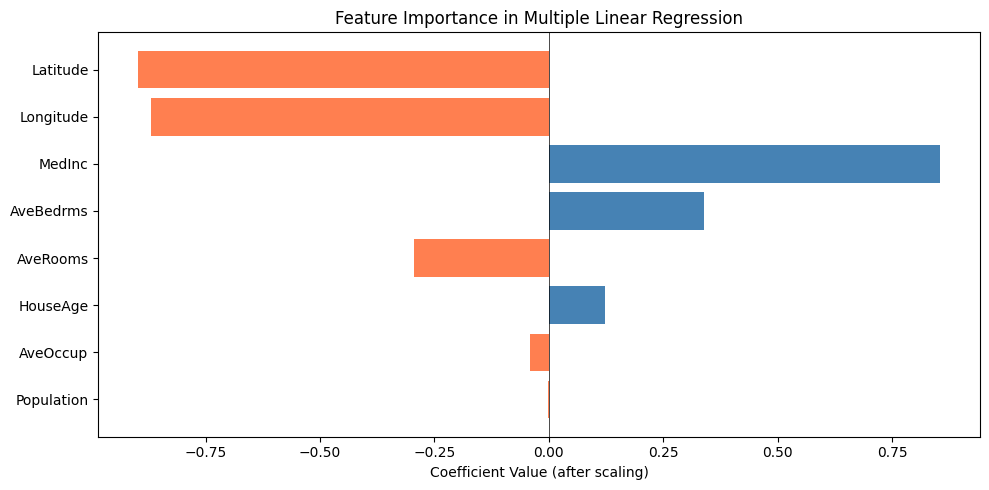

In [21]:
# Extract learned coefficients
lr_model = pipe_lr.named_steps['lr']
feature_names = housing.feature_names  # or df.drop(columns=['MedHouseVal']).columns

# Since we scaled, coefficients are comparable
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("Feature Importance (by |coefficient|):")
print(coef_df.to_string(index=False))

# Visualize
plt.figure(figsize=(10, 5))

colors = ['steelblue' if c > 0 else 'coral' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)

plt.xlabel('Coefficient Value (after scaling)')
plt.title('Feature Importance in Multiple Linear Regression')
plt.axvline(x=0, color='black', linewidth=0.5)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

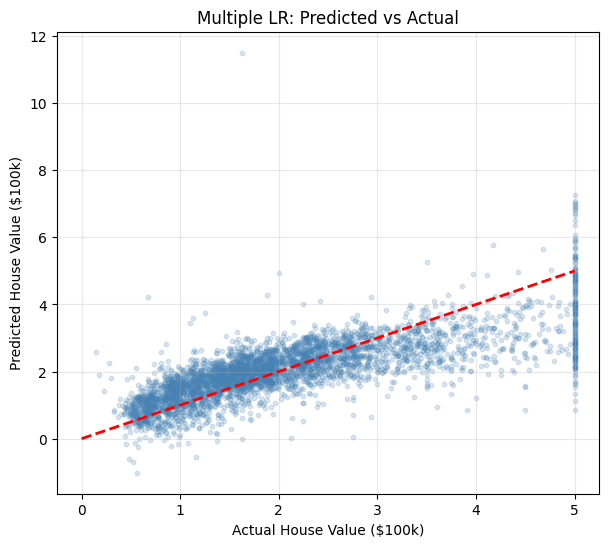

In [22]:
plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred_multi, alpha=0.2, s=10, color='steelblue')
plt.plot([0, 5], [0, 5], 'r--', linewidth=2)
plt.xlabel('Actual House Value ($100k)')
plt.ylabel('Predicted House Value ($100k)')
plt.title('Multiple LR: Predicted vs Actual')
plt.grid(True, alpha=0.3)
plt.show()

##Task4
1. Top 3 (highest impact):

- MedInc

- Latitude

- Longitude

Bottom 3
- Population

- AveBedrms

- AveRooms

it does make sense

2. Because moving north (higher latitude) in California often means going away from some of the most expensive coastal/metro areas,So as Latitude increases, predicted house value tends to decrease, which appears as a negative coefficient

3. multiple regression is better because it uses all 8 features instead of one

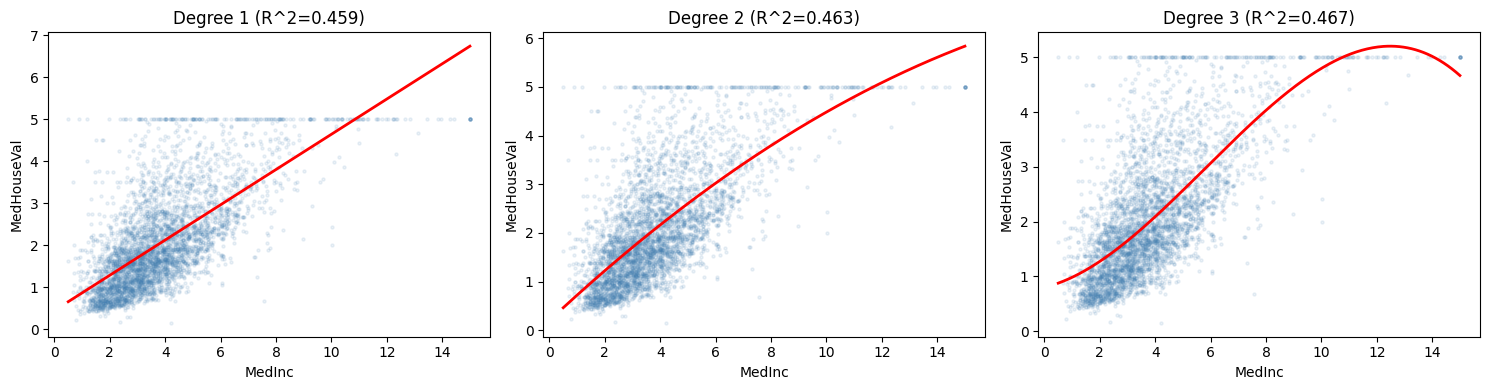

Polynomial Degree Comparison (MedInc only):
Degree 1: R^2=0.4589, RMSE=0.8421
Degree 2: R^2=0.4633, RMSE=0.8386
Degree 3: R^2=0.4671, RMSE=0.8356


In [23]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Use only MedInc
X_simple = df[['MedInc']].values
y = df['MedHouseVal'].values

X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Try degrees 1, 2, and 3
results = {}
plt.figure(figsize=(15, 4))

for i, degree in enumerate([1, 2, 3]):
    pipe_poly = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('lr', LinearRegression())
    ])

    pipe_poly.fit(X_train_s, y_train)
    y_pred = pipe_poly.predict(X_test_s)

    r2_val = r2_score(y_test, y_pred)
    rmse_val = np.sqrt(mean_squared_error(y_test, y_pred))

    results[degree] = {'R2': r2_val, 'RMSE': rmse_val}

    # Plot
    ax = plt.subplot(1, 3, i + 1)
    ax.scatter(X_test_s, y_test, alpha=0.1, s=5, color='steelblue')

    x_plot = np.linspace(X_test_s.min(), X_test_s.max(), 300).reshape(-1, 1)
    y_plot = pipe_poly.predict(x_plot)

    ax.plot(x_plot, y_plot, color='red', linewidth=2)
    ax.set_title(f'Degree {degree} (R^2={r2_val:.3f})')
    ax.set_xlabel('MedInc')
    ax.set_ylabel('MedHouseVal')

plt.tight_layout()
plt.show()

# Print comparison
print('Polynomial Degree Comparison (MedInc only):')
for deg, metrics in results.items():
    print(f"Degree {deg}: R^2={metrics['R2']:.4f}, RMSE={metrics['RMSE']:.4f}")

In [24]:
from sklearn.preprocessing import StandardScaler

# Use all features
X_all = df.drop(columns=['MedHouseVal']).values
y = df['MedHouseVal'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

pipe_poly_all = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('lr', LinearRegression())
])

pipe_poly_all.fit(X_train, y_train)
y_pred_poly = pipe_poly_all.predict(X_test)

r2_poly = r2_score(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))

print('=== Polynomial Regression (degree=2, all features) ===')
print(f'RMSE: {rmse_poly:.4f}')
print(f'R^2: {r2_poly:.4f} ({r2_poly*100:.1f}% variance explained)')

# How many features now?
poly_features = pipe_poly_all.named_steps['poly']
print("\nOriginal features: 8")
print("After degree-2 expansion:", poly_features.n_output_features_)

=== Polynomial Regression (degree=2, all features) ===
RMSE: 0.6814
R^2: 0.6457 (64.6% variance explained)

Original features: 8
After degree-2 expansion: 44


In [25]:
pipe_deg5 = Pipeline([
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('lr', LinearRegression())
])

pipe_deg5.fit(X_train_s, y_train)
y_pred_5 = pipe_deg5.predict(X_test_s)

print("Degree 5 R2:", r2_score(y_test, y_pred_5))
print("Degree 5 RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_5)))

Degree 5 R2: 0.46679559272641336
Degree 5 RMSE: 0.8358922433716712


In [26]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly3 = poly3.fit_transform(X_train)
print("Degree 3 feature count:", X_train_poly3.shape[1])

Degree 3 feature count: 164


##Task 5

1. Degree 3 performs the best
2. Degree 5 does not improve performance. R² slightly decreases, showing that increasing complexity may lead to overfitting.
3. With 8 original features, a degree-3 polynomial expansion creates 164 features.

In [27]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Split data (reuse X_all from earlier)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

# Define models with pipelines
models = {
    'LinearRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Ridge (alpha=1.0)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0, random_state=42))
    ]),

    'Lasso (alpha=0.01)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.01, random_state=42))
    ]),

    'ElasticNet (alpha=0.01)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=42))
    ])
}

print(f"{'Model':<28} {'RMSE':>8} {'MAE':>8} {'R2':>8}")
print("-"*56)

results_dict = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    rmse_val = np.sqrt(mean_squared_error(y_test, y_pred))
    mae_val = mean_absolute_error(y_test, y_pred)
    r2_val = r2_score(y_test, y_pred)

    results_dict[name] = {'RMSE': rmse_val, 'MAE': mae_val, 'R2': r2_val}

    print(f"{name:<28} {rmse_val:>8.4f} {mae_val:>8.4f} {r2_val:>8.4f}")

Model                            RMSE      MAE       R2
--------------------------------------------------------
LinearRegression               0.7456   0.5332   0.5758
Ridge (alpha=1.0)              0.7456   0.5332   0.5758
Lasso (alpha=0.01)             0.7404   0.5353   0.5816
ElasticNet (alpha=0.01)        0.7416   0.5341   0.5803


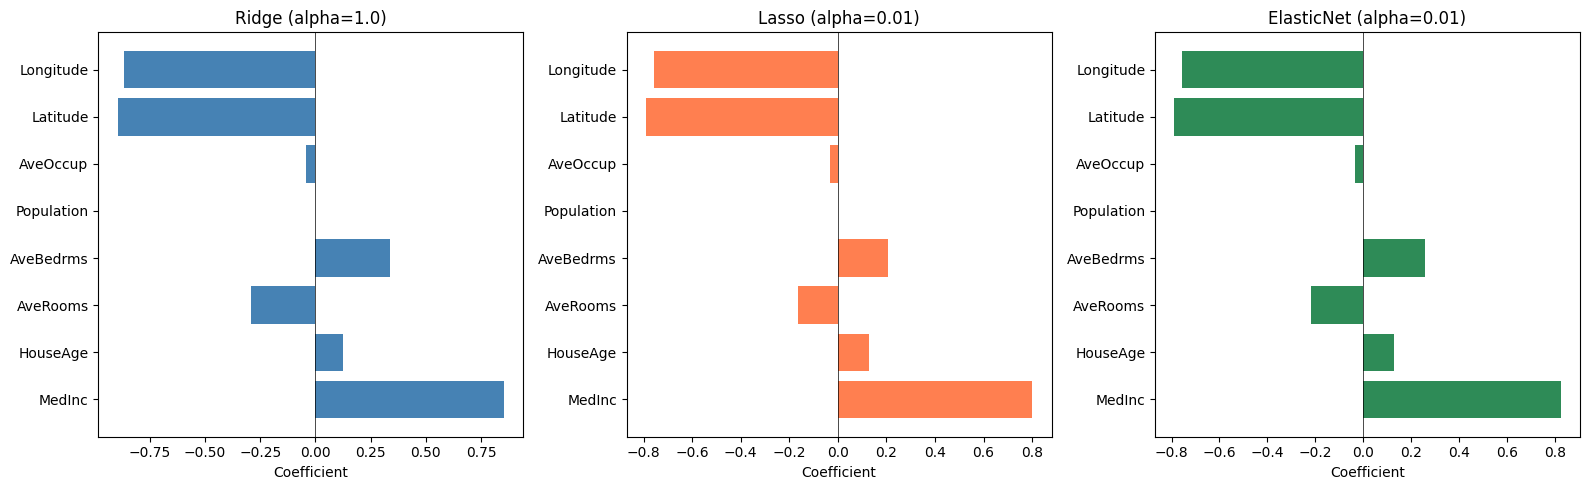

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))

model_names = ['Ridge (alpha=1.0)', 'Lasso (alpha=0.01)', 'ElasticNet (alpha=0.01)']
colors_list = ['steelblue', 'coral', 'seagreen']

for ax, name, color in zip(axes, model_names, colors_list):

    coefs = models[name].named_steps['model'].coef_

    ax.barh(housing.feature_names, coefs, color=color)
    ax.set_title(name)
    ax.axvline(x=0, color='black', linewidth=0.5)
    ax.set_xlabel('Coefficient')

plt.tight_layout()
plt.show()


In [29]:
lasso_coefs = models['Lasso (alpha=0.01)'].named_steps['model'].coef_

print("\nLasso coefficients:")

for feat, coef in zip(housing.feature_names, lasso_coefs):
    status = "-> REMOVED" if abs(coef) < 0.001 else ""
    print(f"{feat:12}: {coef:>8.4f} {status}")


Lasso coefficients:
MedInc      :   0.8010 
HouseAge    :   0.1271 
AveRooms    :  -0.1628 
AveBedrms   :   0.2062 
Population  :  -0.0000 -> REMOVED
AveOccup    :  -0.0306 
Latitude    :  -0.7901 
Longitude   :  -0.7557 


##Task 6
1. As Alpha increases, the regularization becomes stronger
2. 1 eliminated feature
3. In ElasticNet, l1_ratio = 0 behaves like Ridge, while l1_ratio = 1 behaves like Lasso.

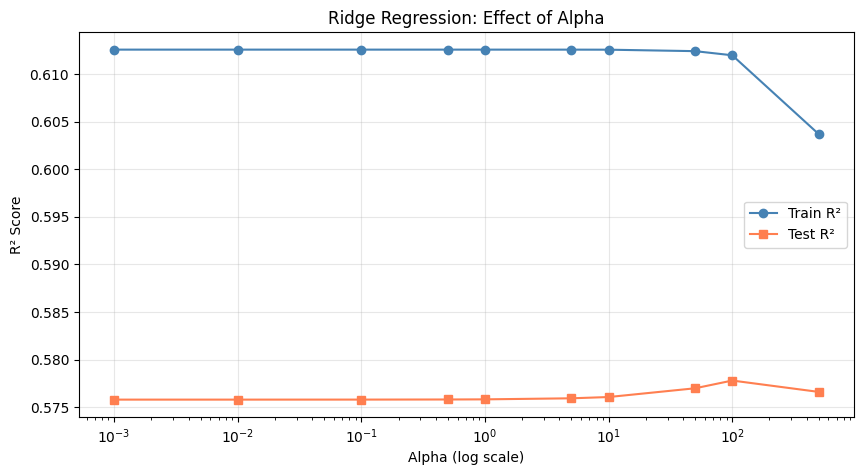

Best alpha: 100.0
Best test R²: 0.5778


In [30]:
alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]

train_scores = []
test_scores = []

for alpha in alphas:

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=alpha))
    ])

    pipe.fit(X_train, y_train)

    train_scores.append(r2_score(y_train, pipe.predict(X_train)))
    test_scores.append(r2_score(y_test, pipe.predict(X_test)))

# Plot
plt.figure(figsize=(10,5))

plt.semilogx(alphas, train_scores, 'o-', label='Train R²', color='steelblue')
plt.semilogx(alphas, test_scores, 's-', label='Test R²', color='coral')

plt.xlabel('Alpha (log scale)')
plt.ylabel('R² Score')
plt.title('Ridge Regression: Effect of Alpha')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Best alpha
best_idx = np.argmax(test_scores)

print("Best alpha:", alphas[best_idx])
print("Best test R²:", round(test_scores[best_idx],4))

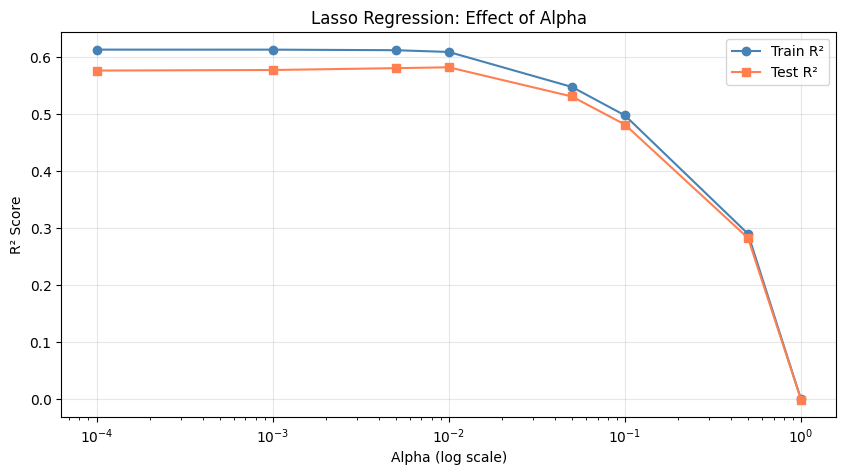

alpha=0.0001  Test R²=0.5759  Features kept=8
alpha=0.001   Test R²=0.5769  Features kept=8
alpha=0.005   Test R²=0.5801  Features kept=7
alpha=0.01    Test R²=0.5816  Features kept=7
alpha=0.05    Test R²=0.5305  Features kept=4
alpha=0.1     Test R²=0.4814  Features kept=3
alpha=0.5     Test R²=0.2827  Features kept=1
alpha=1.0     Test R²=-0.0002  Features kept=0

Best alpha: 0.01
Best test R²: 0.5816


In [31]:
from sklearn.linear_model import Lasso

alphas = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]

train_scores = []
test_scores = []
features_kept = []

for alpha in alphas:

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha=alpha, random_state=42))
    ])

    pipe.fit(X_train, y_train)

    y_train_pred = pipe.predict(X_train)
    y_test_pred = pipe.predict(X_test)

    train_scores.append(r2_score(y_train, y_train_pred))
    test_scores.append(r2_score(y_test, y_test_pred))

    # Count features kept
    coefs = pipe.named_steps['lasso'].coef_
    features_kept.append(np.sum(coefs != 0))

# Plot
plt.figure(figsize=(10,5))

plt.semilogx(alphas, train_scores, 'o-', label='Train R²', color='steelblue')
plt.semilogx(alphas, test_scores, 's-', label='Test R²', color='coral')

plt.xlabel('Alpha (log scale)')
plt.ylabel('R² Score')
plt.title('Lasso Regression: Effect of Alpha')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print results
for a, r2, feat in zip(alphas, test_scores, features_kept):
    print(f"alpha={a:<6}  Test R²={r2:.4f}  Features kept={feat}")

# Best alpha
best_idx = np.argmax(test_scores)

print("\nBest alpha:", alphas[best_idx])
print("Best test R²:", round(test_scores[best_idx],4))

##Task 7

As alpha increases, Lasso starts removing features more aggressively, this becomes clear starting around alpha = 0.05, where the kept features drop from 7 to 4, and it gets even stronger at 0.1 (3 features), 0.5 (1 feature), and 1.0 (0 features).

The best performance happened at alpha = 0.01, where the best test R^2= 0.5816, R^2=0.5816 and Lasso kept 7 features.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Rebuild train/test split (same split for fair comparison)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

all_models = {
    'Simple LR (MedInc)': Pipeline([
        ('lr', LinearRegression())
    ]),

    'Multiple LR (all)': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LinearRegression())
    ]),

    'Polynomial (deg=2)': Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('lr', LinearRegression())
    ]),

    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0))
    ]),

    'Lasso': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.01))
    ]),

    'ElasticNet': Pipeline([
        ('scaler', StandardScaler()),
        ('model', ElasticNet(alpha=0.01, l1_ratio=0.5))
    ])
}

print(f"{'Model':<25} {'RMSE':>8} {'MAE':>8} {'R^2':>8} {'# Features':>10}")
print("-" * 67)

comparison_data = []

for name, pipe in all_models.items():

    # Simple LR uses only MedInc column (column 0)
    if 'Simple' in name:
        X_tr = X_train[:, [0]]
        X_te = X_test[:, [0]]
    else:
        X_tr, X_te = X_train, X_test

    pipe.fit(X_tr, y_train)
    y_pred = pipe.predict(X_te)

    rmse_v = np.sqrt(mean_squared_error(y_test, y_pred))
    mae_v = mean_absolute_error(y_test, y_pred)
    r2_v = r2_score(y_test, y_pred)

    # Count effective features
    if 'poly' in pipe.named_steps:
        n_feat = pipe.named_steps['poly'].n_output_features_
    elif 'Simple' in name:
        n_feat = 1
    else:
        n_feat = X_train.shape[1]

    comparison_data.append({
        'Model': name,
        'RMSE': rmse_v,
        'MAE': mae_v,
        'R2': r2_v,
        'Features': n_feat
    })

    print(f"{name:<25} {rmse_v:>8.4f} {mae_v:>8.4f} {r2_v:>8.4f} {n_feat:>10}")

Model                         RMSE      MAE      R^2 # Features
-------------------------------------------------------------------
Simple LR (MedInc)          0.8421   0.6299   0.4589          1
Multiple LR (all)           0.7456   0.5332   0.5758          8
Polynomial (deg=2)          0.6814   0.4670   0.6457         44
Ridge                       0.7456   0.5332   0.5758          8
Lasso                       0.7404   0.5353   0.5816          8
ElasticNet                  0.7416   0.5341   0.5803          8


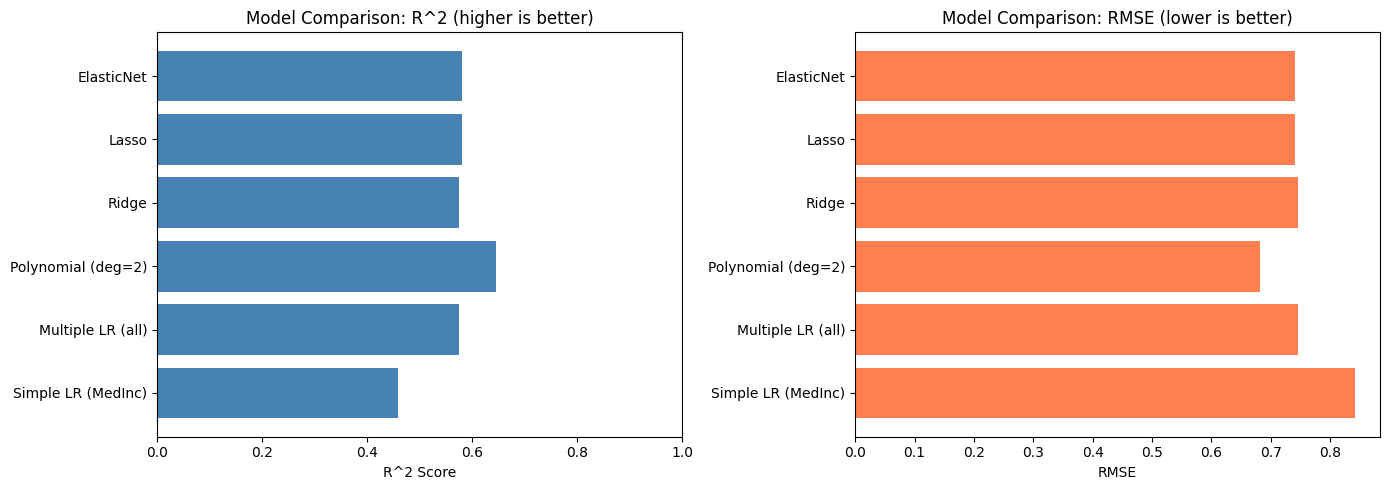

In [33]:
comp_df = pd.DataFrame(comparison_data)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R^2 comparison
axes[0].barh(comp_df['Model'], comp_df['R2'], color='steelblue')
axes[0].set_xlabel('R^2 Score')
axes[0].set_title('Model Comparison: R^2 (higher is better)')
axes[0].set_xlim(0, 1)

# RMSE comparison
axes[1].barh(comp_df['Model'], comp_df['RMSE'], color='coral')
axes[1].set_xlabel('RMSE')
axes[1].set_title('Model Comparison: RMSE (lower is better)')

plt.tight_layout()
plt.show()

##Task 8
1. The Polynomial Regression (degree 2) achieved the highest R^2 = 0.6457 R^2=0.6457 and also had the lowest RMSE = 0.6814, it produced the most accurate predictions among all the models
2. it increases the number of features from 8 to 44, making the model more complex. The improvement may be worth it if accuracy is very important, but simpler models may still be preferred for interpretability
3. I would choose the Multiple Linear Regression, because it provides good accuracy while remaining simple
4. because the dataset has only 8 features and limited multicollinearity

In [34]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 500

cities = np.random.choice(
    ['Jeddah', 'Riyadh', 'Dammam', 'Makkah', 'Madinah'],
    n, p=[0.30, 0.30, 0.15, 0.15, 0.10])

# Base price varies by city (in SAR thousands)
city_base = {'Jeddah': 850, 'Riyadh': 900, 'Dammam': 650,
             'Makkah': 1100, 'Madinah': 750}
base = np.array([city_base[c] for c in cities], dtype=float)

area = np.round(np.random.uniform(80, 400, n), 1)
bedrooms = np.random.randint(1, 7, n)
bathrooms = np.random.randint(1, 5, n)
age = np.random.randint(0, 40, n)
floor = np.random.randint(1, 15, n)
has_parking = np.random.choice([0, 1], n, p=[0.3, 0.7])

# Generate price with realistic relationships
price = (base
         + 3.5 * area
         + 80 * bedrooms
         + 50 * bathrooms
         - 12 * age
         + 15 * floor
         + 100 * has_parking
         + np.random.normal(0, 150, n)) # noise

price = np.round(np.maximum(price, 200), 1)

df_saudi = pd.DataFrame({
    'city': cities,
    'area_sqm': area,
    'bedrooms': bedrooms,
    'bathrooms': bathrooms,
    'age_years': age,
    'floor': floor,
    'has_parking': has_parking,
    'price_kSAR': price # price in thousands of SAR
})

df_saudi.to_csv('saudi_housing.csv', index=False)
print(f'Dataset shape: {df_saudi.shape}')
print(df_saudi.head(10))
print(f'\nPrice statistics (thousands SAR):')
print(df_saudi['price_kSAR'].describe().round(1))

Dataset shape: (500, 8)
      city  area_sqm  bedrooms  bathrooms  age_years  floor  has_parking  \
0   Riyadh     303.4         4          4         24     11            0   
1  Madinah     251.6         6          4          1      1            1   
2   Dammam     179.0         3          1         34     14            0   
3   Riyadh     340.4         5          3          6     14            1   
4   Jeddah     299.1         1          3         20      6            0   
5   Jeddah     132.0         5          4         17     13            1   
6   Jeddah     371.5         6          2          2      6            0   
7   Makkah     343.2         6          3         38      1            1   
8   Dammam     383.9         1          3         10     11            1   
9   Dammam     312.2         2          1         38     13            0   

   price_kSAR  
0      2527.3  
1      2491.2  
2      1345.8  
3      2941.9  
4      2022.0  
5      2264.8  
6      2821.1  
7      2532

#Task 9

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("saudi_housing.csv")

print(df.head())
print(df.describe())

      city  area_sqm  bedrooms  bathrooms  age_years  floor  has_parking  \
0   Riyadh     303.4         4          4         24     11            0   
1  Madinah     251.6         6          4          1      1            1   
2   Dammam     179.0         3          1         34     14            0   
3   Riyadh     340.4         5          3          6     14            1   
4   Jeddah     299.1         1          3         20      6            0   

   price_kSAR  
0      2527.3  
1      2491.2  
2      1345.8  
3      2941.9  
4      2022.0  
         area_sqm    bedrooms   bathrooms   age_years       floor  \
count  500.000000  500.000000  500.000000  500.000000  500.000000   
mean   234.224800    3.502000    2.448000   19.600000    7.522000   
std     91.359246    1.714607    1.128647   11.597111    3.970522   
min     81.500000    1.000000    1.000000    0.000000    1.000000   
25%    153.350000    2.000000    1.000000   10.000000    4.000000   
50%    231.000000    3.000000    


Correlation with price:
price_kSAR     1.000000
area_sqm       0.730056
bedrooms       0.300025
bathrooms      0.090535
floor          0.071430
has_parking    0.023281
age_years     -0.366188
Name: price_kSAR, dtype: float64


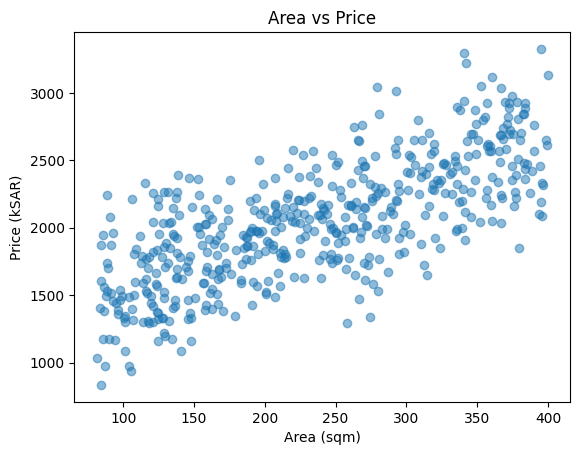

In [39]:
print("\nCorrelation with price:")
print(df.corr(numeric_only=True)['price_kSAR'].sort_values(ascending=False))

# Scatter plot for area vs price
plt.scatter(df['area_sqm'], df['price_kSAR'], alpha=0.5)
plt.xlabel("Area (sqm)")
plt.ylabel("Price (kSAR)")
plt.title("Area vs Price")
plt.show()

from sklearn.model_selection import train_test_split

df_encoded = pd.get_dummies(df, columns=['city'], drop_first=True)

X = df_encoded.drop('price_kSAR', axis=1)
y = df_encoded['price_kSAR']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train_simple = X_train[['area_sqm']]
X_test_simple = X_test[['area_sqm']]

lr = LinearRegression()
lr.fit(X_train_simple, y_train)

y_pred = lr.predict(X_test_simple)

print("\nSimple Linear Regression")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))


Simple Linear Regression
RMSE: 334.66612701326574
MAE: 276.0583547549863
R2: 0.4931641174923733


In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

pipe_lr.fit(X_train, y_train)

y_pred = pipe_lr.predict(X_test)

print("\nMultiple Linear Regression")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))


Multiple Linear Regression
RMSE: 173.02952202197696
MAE: 137.30121409036138
R2: 0.8645171715702978


In [42]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5)
}

results = {}

for name, model in models.items():

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results[name] = (rmse, mae, r2)

    print(f"\n{name}")
    print("RMSE:", rmse)
    print("MAE:", mae)
    print("R2:", r2)


Ridge
RMSE: 173.22333144572758
MAE: 137.4688360927164
R2: 0.8642134944377979

Lasso
RMSE: 173.03334734147964
MAE: 137.30670756787384
R2: 0.8645111810222261

ElasticNet
RMSE: 173.4443216389382
MAE: 137.73690039790773
R2: 0.8638668133421289


In [43]:
lasso_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Lasso(alpha=0.01))
])

lasso_pipe.fit(X_train, y_train)

coeffs = lasso_pipe.named_steps['model'].coef_

print("\nLasso Feature Importance:")
for feature, coef in zip(X.columns, coeffs):
    print(feature, ":", round(coef,3))


Lasso Feature Importance:
area_sqm : 333.997
bedrooms : 142.301
bathrooms : 53.946
age_years : -128.051
floor : 74.014
has_parking : 42.223
city_Jeddah : 104.627
city_Madinah : 39.818
city_Makkah : 193.2
city_Riyadh : 124.383


In [44]:
comparison = []

models_all = {
    "Simple LR": lr,
    "Multiple LR": pipe_lr,
    "Ridge": Pipeline([('scaler', StandardScaler()),('model', Ridge(alpha=1.0))]),
    "Lasso": Pipeline([('scaler', StandardScaler()),('model', Lasso(alpha=0.01))]),
    "ElasticNet": Pipeline([('scaler', StandardScaler()),('model', ElasticNet(alpha=0.01,l1_ratio=0.5))])
}

for name, model in models_all.items():

    if name == "Simple LR":
        model.fit(X_train_simple, y_train)
        y_pred = model.predict(X_test_simple)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    comparison.append([name, rmse, mae, r2])

comp_df = pd.DataFrame(comparison,
                       columns=['Model','RMSE','MAE','R2'])

print("\nModel Comparison")
print(comp_df)


Model Comparison
         Model        RMSE         MAE        R2
0    Simple LR  334.666127  276.058355  0.493164
1  Multiple LR  173.029522  137.301214  0.864517
2        Ridge  173.223331  137.468836  0.864213
3        Lasso  173.033347  137.306708  0.864511
4   ElasticNet  173.444322  137.736900  0.863867


#Summary

In this lab, First, I checked the dataset using functions like df.info() and df.head() to understand the columns and data types, then I then trained a model using MedInc (Median Income) as the main feature, then I trained another model using HouseAge instead of MedInc, at the end MedInc works better than HouseAge for predicting house values because it has a stronger relationship with the target variable.

it was a heavy and clear lab.